<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




# `Instrucciones generales`

Esta es la parte III del proyecto, considerá ultizar tus resultados anteriores
y reciclar el código anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**


Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3


In [2]:
# Coloque aquí todas las importaciones que considere necesarias.
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estado del Taller

| Pregunta | Estado del código | Estado del análisis escrito |
| :--- | :--- | :--- |
| **1.1 XAI, LIME y SHAP** | No requiere código | Definiciones presentes, requieren matices y correcciones |
| **1.1 Escenario de riesgo** | 10 frases implementadas | Dos escenarios propuestos, sin elección definitiva ni hipótesis individuales |
| **1.2 Predicciones BETO** | Completo | Falta comparar resultados con hipótesis |
| **1.2 Explicaciones LIME** | Cinco gráficos completos | Falta interpretar las contribuciones y riesgos |
| **2.1 Limpieza** | Ejecutada | Falta justificar clasificación y selección de variables |
| **2.2 División** | Correcta | Podría explicarse el uso de estratificación |
| **2.3 Estandarización** | Ejecutada | Justificación breve, pero mejorable |
| **2.4 Random Forest** | Completo | Falta interpretar métricas y consecuencias |
| **2.5 SHAP** | Gráficos y tabla completos | Falta interpretación global, local y discusión ética |

# Parte 1: Interpretabilidad local con LIME

## Motivación

Un modelo de clasificación de texto puede tener buen desempeño agregado y aun así fallar sistemáticamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado políticamente. Estas fallas suelen ser invisibles si solo miramos métricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una predicción individual y preguntar: ¿qué palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite múltiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo específico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su análisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotécnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificación tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza cómo se comunica un diagnóstico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.

**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

## Parte 1.2: Aplicación de LIME

1. Carguen el modelo BETO de análisis de sentimientos.

2. Obtengan la predicción del modelo para cada frase y comparen los resultados con su hipótesis de 1.1: ¿se cumplió lo que esperaban?

3. Apliquen LIME para obtener la explicación local de al menos 5 frases, priorizando aquellas donde el modelo se comportó de forma inesperada o donde identifiquen un problema ético. Si no encuentran ningún problema, justifiquen esa conclusión. Para cada una, visualicen las contribuciones de cada palabra mediante un gráfico de barras.

4. Interpreten los resultados: ¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

# Respuestas Parte 1
## Parte 1.1: Contexto

0. ¿Qué es XAI, LIME Y SHAP?

XAI o Explainable Artificial Intelligence (Inteligencia Artificial Explicable): Es un conjunto de técnicas que buscan que las decisiones que toman los modelos de inteligencia artificial puedan ser comprendidos por los humanos. Estas técnicas se aplican especialmente a modelos de "caja negra" o "black box" como redes neuronales o ensambles complejos, donde no sabemos como funciona el algoritmo en su interior. El objetivo es generar confianza, identificar sesgos y asegurar que el modelo no esté aprendiendo de patrones incorrectos o indeseables.

LIME o Local Interpretable Model-agnostic Explanations: Es una técnica de inteligencia artifical de interpretabilidad local. Explica predicciones individuales, es decir, de un caso específico, cambiando la entrada. Esta técnica oculta palabras de un texto, por ejemplo, y observa cómo cambia la predicción. LIME construye un modelo lineal simple y explicable en la "vecindad" de esa predicción específica. Es una técnica agnóstica, es decir, funciona con cualquier tipo de algoritmo complejo, ya sean redes neuronales, bosques aleatorios (random forest) u otros sistemas.

SHAP o Shapley Additive Explanations (Explicaciones Aditivas de Shapley): Se basa en la teoría de juegos, SHAP asigna a cada variable o característica un valor de importancia para una predicción en particular. A diferencia de LIME, SHAP ofrece consistencia teórica y permite iterpretabilidad local y global, es decir, de una predicción y del comportamiento generla del modelo.

Tanto LIME como SHAP son técnicas XAI, y se utilizan para aplicar transparencia, identificar sesgos y depurar errores en los modelos mas avanzados de inteligencia artificial.


### Escenario de Riesgo:
Un organismo público utiliza un sistema sociotécnico de IA para analizar y clasificar automáticamente el tono y contenido de las notificaciones enviadas a postulantes de ayudas sociales. Creemos que las siguientes frases son relevantes por ser posibles casos en los que se de una clasificacion erronea por las siguientes razones:
1. El modelo podria dar una mayor ponderacion a palabras de cortesia (Nos alegra, Lamentamos, Nos complace) usadas a la hora de dar la notificacion, influenciando a dar una clasificacion contraria a la que deberia generar el estado de su solicitud
2. Palabras usadas solamente de forma informativa sobre condiciones socioeconómicas (Pobreza, Vulnerabilidad) corren el riesgo de ser etiquetadas equivocadamente como negativas solo por incluir términos asociados a carencias sociales.
3. El uso de expresiones ambiguas o ironicas pueden confundir al modelo a la hora de categorizar correctamente

10 frases del escenario de riesgo 2:

    1. "Nos alegra comunicarle que su solicitud de subsidio habitacional ha sido aprobada."
    2. "Lamentamos informarle que su solicitud de apoyo económico ha sido rechazada."
    3. "Nos complace informarle que, lamentablemente, usted no cumple los requisitos para recibir el beneficio."
    4. "Aunque su familia atraviesa una situación económica difícil, su solicitud de ayuda ha sido aprobada."
    5. "Su postulación ha sido declarada inadmisible por incumplimiento de los requisitos establecidos."
    6. "Gracias a su condición de vulnerabilidad, su familia recibirá un aporte económico adicional."
    7. "Su solicitud no ha sido rechazada, pero todavía se encuentra en evaluación."
    8. "Buenas noticias: este mes no recibirá el subsidio que esperaba."
    9. "Su beneficio ha sido aprobado, aunque el monto asignado será inferior al solicitado."
    10. "La evaluación socioeconómica determinó que su hogar pertenece a un grupo de alta vulnerabilidad."

In [3]:
frases = [
    "Nos alegra comunicarle que su solicitud de subsidio habitacional ha sido aprobada.",
    "Lamentamos informarle que su solicitud de apoyo económico ha sido rechazada.",
    "Nos complace informarle que, lamentablemente, usted no cumple los requisitos para recibir el beneficio.",
    "Aunque su familia atraviesa una situación económica difícil, su solicitud de ayuda ha sido aprobada.",
    "Su postulación ha sido declarada inadmisible por incumplimiento de los requisitos establecidos.",
    "Gracias a su condición de vulnerabilidad, su familia recibirá un aporte económico adicional.",
    "Su solicitud no ha sido rechazada, pero todavía se encuentra en evaluación.",
    "Buenas noticias: este mes no recibirá el subsidio que esperaba.",
    "Su beneficio ha sido aprobado, aunque el monto asignado será inferior al solicitado.",
    "La evaluación socioeconómica determinó que su hogar pertenece a un grupo de alta vulnerabilidad."
]

print("Cantidad de frases:", len(frases))

Cantidad de frases: 10


## Parte 1.2: Aplicación de LIME

In [4]:
# Carga de modelo BETO
beto = pipeline(
    "text-classification",
    model="finiteautomata/beto-sentiment-analysis"
)

# Etiquetas usando beto
etiquetas = [
    beto.model.config.id2label[i]
    for i in range(beto.model.config.num_labels)
]

print("Clases del modelo:", etiquetas)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 29620.37it/s]


Clases del modelo: ['NEG', 'NEU', 'POS']


In [5]:
def obtener_probabilidades(textos):
    resultados = beto(
        list(textos),
        top_k=None,
        truncation=True,
        batch_size=8
    )

    probabilidades = []

    for resultado in resultados:
        probabilidades_frase = []

        for etiqueta in etiquetas:
            for prediccion in resultado:
                if prediccion["label"] == etiqueta:
                    probabilidades_frase.append(prediccion["score"])
                    break
        probabilidades.append(probabilidades_frase)
    return np.array(probabilidades)

In [6]:
# probabilidades de cada frase
probabilidades = obtener_probabilidades(frases)

# tabla de resultados
resultados_beto = pd.DataFrame({
    "Frase": frases,
    "Predicción": [
        etiquetas[i]
        for i in np.argmax(probabilidades, axis=1)
    ],
    "Confianza": np.max(probabilidades, axis=1)
})

# Agregar la probabilidad de cada categoría
for i, etiqueta in enumerate(etiquetas):
    resultados_beto[etiqueta] = probabilidades[:, i]

display(resultados_beto)

,Frase,Predicción,Confianza,NEG,NEU,POS
0,Nos alegra comunicarle que su solicitud de sub...,POS,0.819659,0.001374,0.178966,0.819659
1,Lamentamos informarle que su solicitud de apoy...,NEG,0.990625,0.990625,0.008738,0.000636
2,"Nos complace informarle que, lamentablemente, ...",NEG,0.995990,0.995990,0.003501,0.000509
3,Aunque su familia atraviesa una situación econ...,NEU,0.841210,0.001270,0.841210,0.157520
4,Su postulación ha sido declarada inadmisible p...,NEG,0.767244,0.767244,0.230084,0.002672
5,"Gracias a su condición de vulnerabilidad, su f...",NEU,0.997214,0.001485,0.997214,0.001301
6,"Su solicitud no ha sido rechazada, pero todaví...",NEU,0.890728,0.001072,0.890728,0.108200
7,Buenas noticias: este mes no recibirá el subsi...,NEG,0.995995,0.995995,0.003465,0.000540
8,"Su beneficio ha sido aprobado, aunque el monto...",NEU,0.995863,0.000688,0.995863,0.003449
9,La evaluación socioeconómica determinó que su ...,NEG,0.977020,0.977020,0.021328,0.001652


La gran mayoria de frases fueron clasificadas acorde al resultado de la solicitud, "Positiva" si esta era aprobada, "Negativa" si era rechazada y "Neutra" en casos como "Su beneficio ha sido aprobado, aunque el monto asignado será inferior al solicitado.". Aunque hay algunas frases que podrian estar mal catalogadas:
- (3)  "Aunque su familia atraviesa una situación económica difícil, su solicitud de ayuda ha sido aprobada." fue catalogada como "Neutra" aunque la noticia de haber sido aprobada la ayuda deberia ser postiva, esto posiblemente debido a que se menciona la "situacion economica dificil" por la que pasa la familia
- (5)  Con "Gracias a su condición de vulnerabilidad, su familia recibirá un aporte económico adicional." paso algo parecido al caso anterior, el "aporte economico adicional" deberia ser "Positivo", pero la mencion de "vulnerabilidad" pudo haber influenciado al modelo para catalogarlo como "Neutro"
- (9)  En el caso de "La evaluación socioeconómica determinó que su hogar pertenece a un grupo de alta vulnerabilidad.", al usar expresiones ambiguas es complicado defnir su categoria, ya que la frase como tal se puede considerar "Negativa" si no se tiene en cuenta el hecho de que debido a esto puede acceder a un posible beneficio


Frase 1: Nos alegra comunicarle que su solicitud de subsidio habitacional ha sido aprobada.
Predicción: POS
[(np.str_('alegra'), 0.6171394119378197), (np.str_('aprobada'), 0.4388095327211883), (np.str_('habitacional'), -0.16921731376261084), (np.str_('comunicarle'), -0.11766929478305536), (np.str_('solicitud'), 0.0871496797337175), (np.str_('de'), -0.06999314638506093), (np.str_('Nos'), 0.06043420210272229), (np.str_('subsidio'), -0.048645439588053514), (np.str_('sido'), -0.04015337885046791), (np.str_('ha'), -0.0379859408280538)]


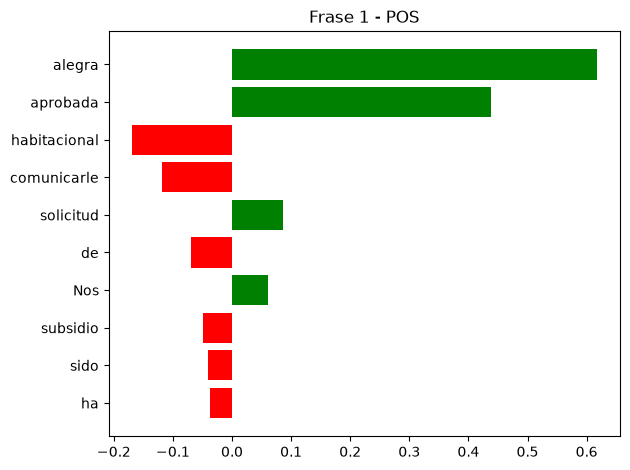


Frase 2: Lamentamos informarle que su solicitud de apoyo económico ha sido rechazada.
Predicción: NEG
[(np.str_('Lamentamos'), 0.44619834427738597), (np.str_('rechazada'), 0.1883122559967828), (np.str_('apoyo'), 0.07760269537655781), (np.str_('informarle'), -0.0768119414647407), (np.str_('sido'), 0.06561470136767071), (np.str_('que'), 0.04570408518051039), (np.str_('ha'), -0.04364601751377417), (np.str_('su'), 0.04166841889908353), (np.str_('económico'), 0.03540833358780435), (np.str_('de'), 0.01802899959758525)]


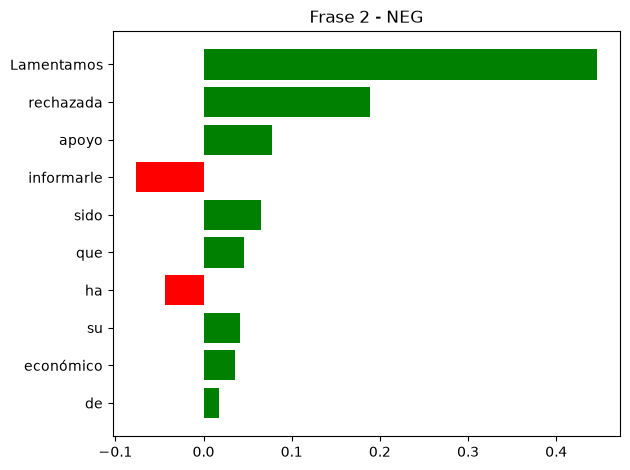


Frase 4: Aunque su familia atraviesa una situación económica difícil, su solicitud de ayuda ha sido aprobada.
Predicción: NEU
[(np.str_('Aunque'), 0.2507978195469491), (np.str_('familia'), 0.10788887647681507), (np.str_('económica'), 0.07267674946441993), (np.str_('aprobada'), 0.06941422391143069), (np.str_('su'), -0.055406354643297906), (np.str_('ha'), 0.053469223999605395), (np.str_('atraviesa'), 0.03656526473638094), (np.str_('difícil'), -0.03414127745247419), (np.str_('situación'), 0.027536671538860212), (np.str_('sido'), 0.02183045572772747)]


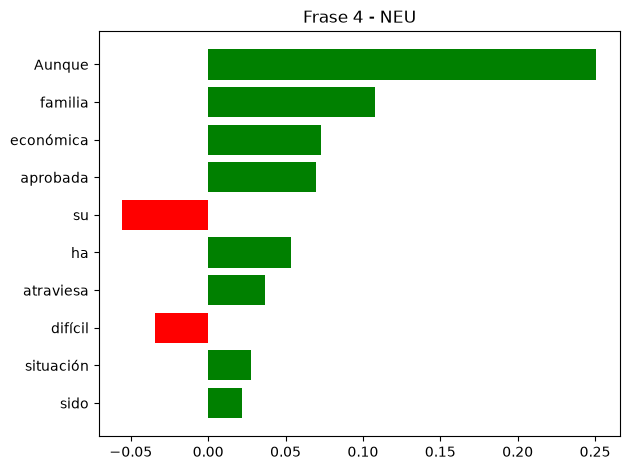


Frase 6: Gracias a su condición de vulnerabilidad, su familia recibirá un aporte económico adicional.
Predicción: NEU
[(np.str_('recibirá'), 0.20016038258543684), (np.str_('económico'), 0.19221450459866818), (np.str_('adicional'), 0.16467311883844946), (np.str_('condición'), 0.09670452961233422), (np.str_('aporte'), 0.07071997216068795), (np.str_('de'), 0.060660704963037146), (np.str_('a'), 0.05368558113535934), (np.str_('un'), 0.019980289863085216), (np.str_('vulnerabilidad'), 0.018706031149321782), (np.str_('su'), -0.012283929397953171)]


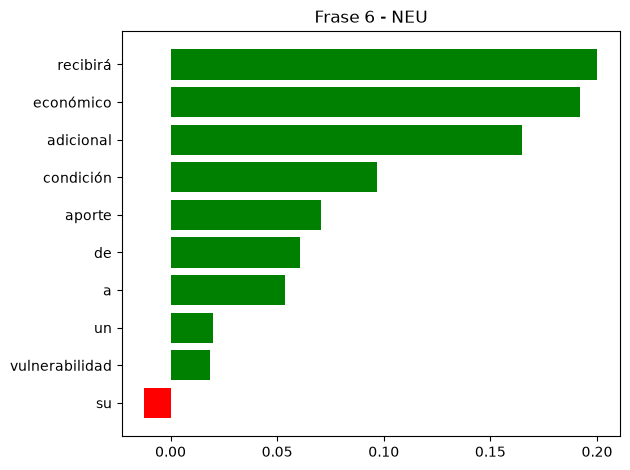


Frase 10: La evaluación socioeconómica determinó que su hogar pertenece a un grupo de alta vulnerabilidad.
Predicción: NEG
[(np.str_('vulnerabilidad'), 0.7790219198721468), (np.str_('alta'), 0.17717342325253035), (np.str_('evaluación'), -0.14348968839013024), (np.str_('La'), -0.11103224869498395), (np.str_('que'), 0.08085408180810236), (np.str_('de'), 0.06543006173605798), (np.str_('un'), 0.050589736518492544), (np.str_('a'), 0.03565022350432362), (np.str_('pertenece'), 0.03312603183059801), (np.str_('determinó'), -0.03252865539985315)]


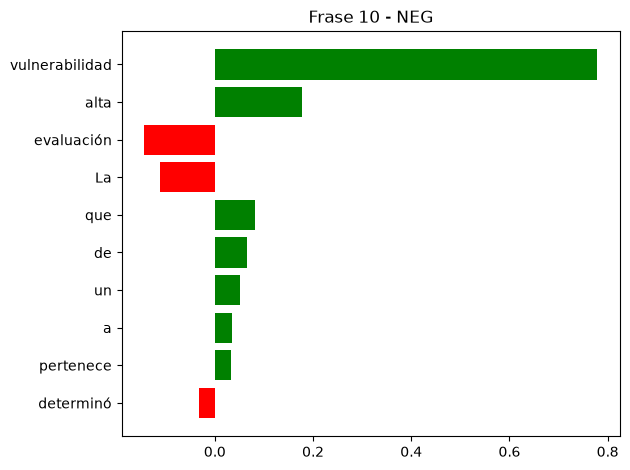

In [9]:
# Explicador Lime
explicador_lime = LimeTextExplainer(
    class_names=etiquetas,
    random_state=42
)

# Índices de las frases seleccionadas
indices_seleccionados = [0, 1, 3, 5, 9]

for indice in indices_seleccionados:

    frase = frases[indice]

    # Obtener la clase predicha
    probabilidades_frase = obtener_probabilidades([frase])[0]
    clase_predicha = int(np.argmax(probabilidades_frase))

    # Construir la explicación LIME
    explicacion = explicador_lime.explain_instance(
        frase,
        obtener_probabilidades,
        labels=[clase_predicha],
        num_features=10,
        num_samples=500
    )

    # Mostrar la información de la frase
    print(f"\nFrase {indice + 1}: {frase}")
    print("Predicción:", etiquetas[clase_predicha])

    # Mostrar la contribución de las palabras
    print(explicacion.as_list(label=clase_predicha))

    # Gráfico de barras
    explicacion.as_pyplot_figure(label=clase_predicha)

    plt.title(
        f"Frase {indice + 1} - {etiquetas[clase_predicha]}"
    )
    plt.tight_layout()
    plt.show()

### 4)
- Frase 1: Las palabras "alegra" y "aprobada" dominan esta prediccion, con +0.61 y +0.43 respectivamente. Como se esperaba la palabra "alegra" si influye en la decision, aunque en este caso la frase se considero bien catalogada, ademas que al ser "aprobada" la segunda palabra que mas influye, no se aleja tanto del resultado esperado.
- Frase 2: Las palabras "lamentamos" y "rechazada" dominan esta prediccion, con +0.44 y +0.18 respectivamente. Algo parecido al caso anterior pero esta vez con algo menos de influencia ambas palabras, aunque sigue pesando mas la palabra de cortesia que el resultado de la solicitud.
- Frase 4: Las palabras "aunque" y "familia" dominan esta prediccion, con +0.25 y +0.10 respectivamente. "Aprobada" y "Economica dificil" no influyen tanto como uno pensaba, no asi el conector "aunque", lo cual tiene bastante sentido al querer conectar dos situaciones contrarias.
- Frase 6: Las palabras "recibira", "economico" y "adicional" dominan esta prediccion, con +0.20, +0.19 y +0.16 respectivamente. Lo cual resulta raro ya que lo que uno pensaria "Positivo" influye bastante al decidir que es "Neutro", y "Vulnerabilidad" no influye casi nada
- Frase 10: La palabra "vulnerabildad" domina esta prediccion con +0.77. Tiene sentido ya que no asocia la alta vulnerabilidad con recibir un apoyo economico

Efectivamente se presentan dos problemas eticos al usar el modelo en este contexto. El primero siendo el clasificar como negativo notificaciones que incluyan palabras "negativas" como el caso de vulnerabilidad, al no entender que este es un requisito objetivo para poder recibir el beneficio. Y el segundo es que se guia mas por las palabras de "cortesia" como "alegra" o "lamentamos" que por el resultado de la notificacion (si esta fue aprobada o no).

# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuarán el trabajo anterior. Usando la limpieza y estandarización que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como mínimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [13]:
import pandas as pd
import numpy as np
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,MinMaxScaler


In [14]:
# Carga del dataset
df_casen = pd.read_csv("data/casen_2024.csv")

# Información general
print("Dimensiones:", df_casen.shape)

print("\nTipos de datos:")
print(df_casen.dtypes)

print("\nValores nulos:")
print(df_casen.isnull().sum())

# Revisar las variables que anteriormente convertiste a enteros
columnas_de_conteo = ["v27a", "v27b", "v29b"]

for columna in columnas_de_conteo:
    print(f"\nVariable: {columna}")
    print(df_casen[columna].describe())
    print("Valores nulos:", df_casen[columna].isnull().sum())

# Convertir a formato numérico sin eliminar decimales
df_casen[columnas_de_conteo] = df_casen[
    columnas_de_conteo
].apply(pd.to_numeric, errors="coerce")

# Variable objetivo
objetivo = "pobreza_multi"

# Revisar distribución de la variable objetivo
print("\nDistribución de pobreza_multi:")
print(df_casen[objetivo].value_counts(dropna=False))

# Eliminar registros sin variable objetivo
df_casen = df_casen.dropna(subset=[objetivo]).copy()

# Columnas a excluir después de revisar el diccionario de datos
# Agregar identificadores o variables que filtren la respuesta
columnas_excluir = []

# Separación de variables predictoras y objetivo
X = df_casen.drop(
    columns=[objetivo] + columnas_excluir
).copy()

y = df_casen[objetivo].copy()

# Codificación de la variable objetivo
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Verificar correspondencia entre etiquetas originales y números
for codigo, categoria in enumerate(label_encoder.classes_):
    print(codigo, ":", categoria)

# Códigos numéricos que representan categorías
# Completar esta lista según el diccionario CASEN
categoricas_codificadas = []

for columna in categoricas_codificadas:
    X[columna] = X[columna].astype("string")

print("\nDimensiones de X:", X.shape)
print("Cantidad de registros en y:", len(y))

Dimensiones: (212471, 42)

Tipos de datos:
area                 str
p1                   str
p2                 int64
p3                 int64
p4                 int64
p9                 int64
tot_per_h          int64
edad               int64
sexo                 str
ind_hacina         int64
e1                   str
e9depen              str
o1               float64
o19                  str
o31                  str
s13                  str
h7e                int64
h7f                int64
r1a                  str
r3                   str
r14                int64
r17a               int64
r17b               int64
r17c               int64
v1                   str
v2                   str
v3                 int64
v4                   str
v5                 int64
v6                   str
v13                  str
v20                  str
v22                  str
v23                int64
v24                  str
v24b             float64
v27a             float64
v27b             float64
v29b   

2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)

In [15]:
# División del conjunto de datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Revisar dimensiones
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Revisar distribución de clases
print("\nClases en entrenamiento:")
print(pd.Series(y_train).value_counts(normalize=True))

print("\nClases en prueba:")
print(pd.Series(y_test).value_counts(normalize=True))

X_train: (169976, 41)
X_test: (42495, 41)

Clases en entrenamiento:
0    0.823546
1    0.176454
Name: proportion, dtype: float64

Clases en prueba:
0    0.823532
1    0.176468
Name: proportion, dtype: float64




2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección






In [16]:
# Copiar los conjuntos para no modificar los originales
X_train = X_train.copy()
X_test = X_test.copy()

# Identificar variables numéricas y categóricas
columnas_numericas = X_train.select_dtypes(
    include="number"
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# Imputar valores faltantes numéricos usando la media
for columna in columnas_numericas:

    media = X_train[columna].mean()

    if pd.isna(media):
        raise ValueError(
            f"La columna {columna} no tiene valores válidos"
        )

    X_train[columna] = X_train[columna].fillna(media)
    X_test[columna] = X_test[columna].fillna(media)

# Imputar valores faltantes categóricos usando la moda
for columna in columnas_categoricas:

    moda = X_train[columna].mode(dropna=True)

    if len(moda) > 0:
        valor_frecuente = moda.iloc[0]
    else:
        valor_frecuente = "Sin información"

    X_train[columna] = X_train[columna].fillna(
        valor_frecuente
    )

    X_test[columna] = X_test[columna].fillna(
        valor_frecuente
    )

In [18]:
# Crear variables dummy en entrenamiento
X_train_codificado = pd.get_dummies(
    X_train,
    columns=columnas_categoricas,
    drop_first=False,
    dtype=int
)

# Crear variables dummy en prueba
X_test_codificado = pd.get_dummies(
    X_test,
    columns=columnas_categoricas,
    drop_first=False,
    dtype=int
)

# Mantener exactamente las mismas columnas
X_test_codificado = X_test_codificado.reindex(
    columns=X_train_codificado.columns,
    fill_value=0
)

print("Entrenamiento:", X_train_codificado.shape)
print("Prueba:", X_test_codificado.shape)

Entrenamiento: (169976, 112)
Prueba: (42495, 112)


In [19]:
# Crear el escalador
escalador = StandardScaler()

# Copiar los conjuntos ya codificados
X_train_escalado = X_train_codificado.copy()
X_test_escalado = X_test_codificado.copy()

# Estandarizar solamente las variables numéricas
X_train_escalado[columnas_numericas] = (
    escalador.fit_transform(
        X_train_codificado[columnas_numericas]
    )
)

X_test_escalado[columnas_numericas] = (
    escalador.transform(
        X_test_codificado[columnas_numericas]
    )
)

# Comprobar resultado
print("Primeras observaciones estandarizadas:")
display(X_train_escalado.head())

print("\nValores nulos restantes:")
print(X_train_escalado.isnull().sum().sum())
print(X_test_escalado.isnull().sum().sum())

Primeras observaciones estandarizadas:


,p2,p3,p4,p9,tot_per_h,edad,ind_hacina,o1,h7e,h7f,...,os1_Bisexual,os1_Gay/Lesbiana,os1_Heterosexual,os1_No sabe,os1_Otra,os1_Prefiere no responder,trans_No,trans_No sabe,trans_Prefiere no responder,trans_Sí
147036,-1.372036,-0.549982,-0.795826,0.226579,0.282643,-0.129438,-0.218261,-1.188852,-0.180716,-0.197245,...,0,0,1,0,0,0,1,0,0,0
57701,-1.372036,-0.549982,0.615190,0.226579,0.282643,-0.390345,-0.218261,-1.188852,-0.180716,-0.197245,...,0,0,1,0,0,0,1,0,0,0
31831,-0.079932,-0.549982,-0.795826,0.226579,0.282643,-1.651400,-0.218261,0.841148,-0.180716,-0.197245,...,0,0,1,0,0,0,1,0,0,0
57549,-1.372036,0.756971,0.615190,-0.944795,-0.942400,0.087985,-0.218261,-1.188852,-0.180716,-0.197245,...,0,0,1,0,0,0,1,0,0,0
208807,-0.079932,0.756971,0.615190,0.226579,0.282643,-0.259892,-0.218261,-1.188852,-0.180716,-0.197245,...,0,0,1,0,0,0,1,0,0,0



Valores nulos restantes:
0
0


Justificación

Se usa StandardScaler porque centra la media en cero y la desviación estándar en 1. Nos sirve para homogenizar magnitudes dispares como la edad.

2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

Accuracy: 0.9355

Matriz de confusión:
[[34902    94]
 [ 2648  4851]]

Reporte de clasificación:
              precision    recall  f1-score   support

    No pobre       0.93      1.00      0.96     34996
       Pobre       0.98      0.65      0.78      7499

    accuracy                           0.94     42495
   macro avg       0.96      0.82      0.87     42495
weighted avg       0.94      0.94      0.93     42495



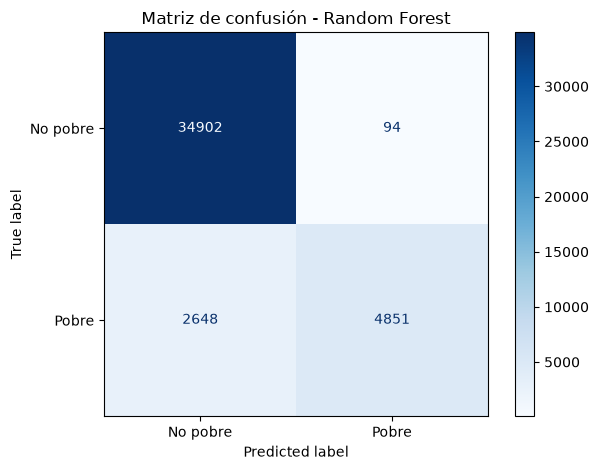

In [20]:
# Entrenamiento del modelo Random Forest
rf_modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_modelo.fit(X_train_escalado, y_train)

# Obtener predicciones del conjunto de prueba
y_predict = rf_modelo.predict(X_test_escalado)

# Exactitud del modelo
accuracy = accuracy_score(y_test, y_predict)

print("Accuracy:", round(accuracy, 4))

# Matriz de confusión
matriz_confusion = confusion_matrix(
    y_test,
    y_predict
)

print("\nMatriz de confusión:")
print(matriz_confusion)

# Reporte de clasificación
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_predict,
        labels=rf_modelo.classes_,
        target_names=[
            str(categoria)
            for categoria in label_encoder.classes_
        ],
        zero_division=0
    )
)

# Gráfico de la matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_predict,
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la predicción y que puede influir en que estas tengan mayor influencia. Considera en tu explicación la relevancia de los resultados en el contexto.

- Preguntas guía para tu respuesta : ¿Qué aporta conocer los valores SHAP? ¿Es una herramienta suficiente en sí misma o puede apoyarse con otras? ¿Cómo afecta la preparación de los datos a las predicciones y su posterior explicación? ¿Es importante tener acceso a ambas interpretaciónes (global y local) en este caso?

In [ ]:
# Seleccionar una muestra del conjunto de prueba
muestra_shap = X_test_escalado.sample(
    n=min(100, len(X_test_escalado)),
    random_state=42
)

# Crear el explicador SHAP
explainer = shap.TreeExplainer(rf_modelo)

# Calcular valores SHAP
valores_shap = explainer.shap_values(muestra_shap)

# Seleccionar la clase codificada como 1
indice_clase = list(rf_modelo.classes_).index(1)

# Compatibilidad con diferentes versiones de SHAP
if isinstance(valores_shap, list):
    shap_clase_1 = valores_shap[indice_clase]

elif valores_shap.ndim == 3:
    shap_clase_1 = valores_shap[:, :, indice_clase]

else:
    shap_clase_1 = valores_shap

print("Dimensiones de los valores SHAP:")
print(shap_clase_1.shape)

print(
    "Clase analizada:",
    label_encoder.inverse_transform([1])[0]
)

# LA CELDA ANTERIOR SE DEMORÓ 15 MINUTOS EN CORRER

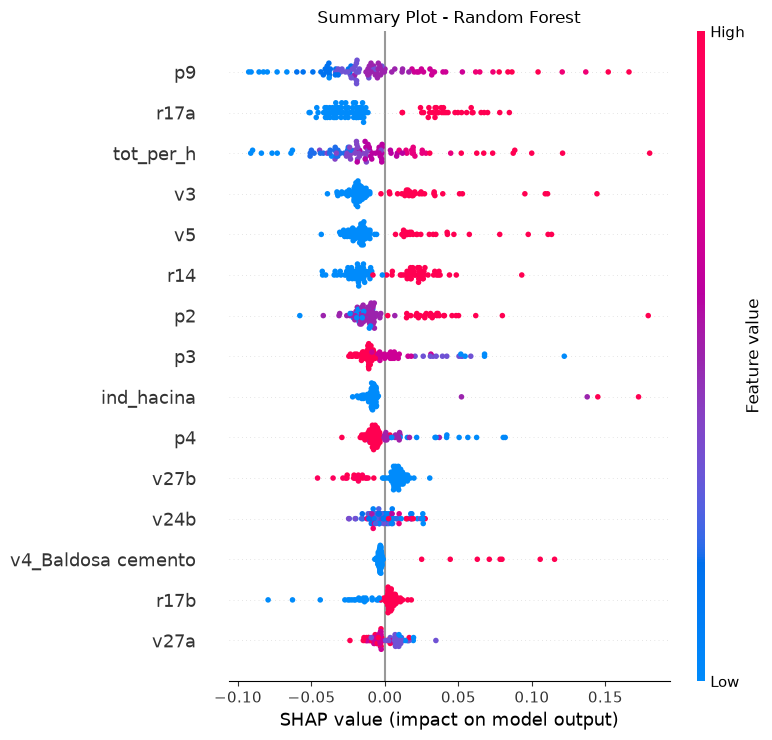

In [25]:
# Visualización global de los valores SHAP
shap.summary_plot(
    shap_clase_1,
    muestra_shap,
    max_display=15,
    show=False
)

plt.title("Summary Plot - Random Forest")
plt.tight_layout()
plt.show()

,Variable,Importancia SHAP
3,p9,0.034988
11,r17a,0.033083
4,tot_per_h,0.030982
14,v3,0.023653
15,v5,0.022855
10,r14,0.021962
0,p2,0.021272
1,p3,0.016658
6,ind_hacina,0.014089
2,p4,0.012563


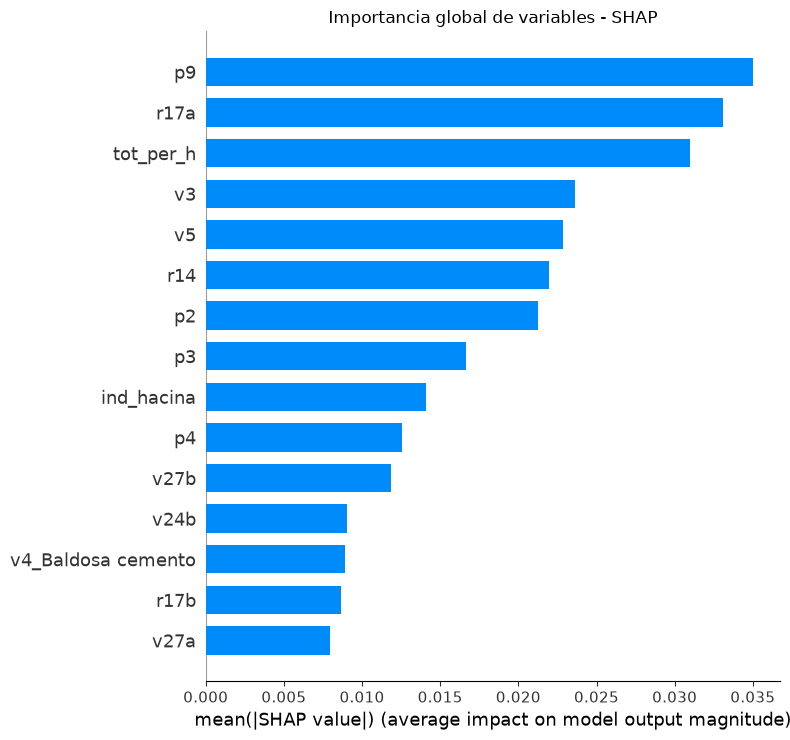

In [26]:
# Calcular importancia media absoluta de SHAP
importancia_shap = np.abs(shap_clase_1).mean(axis=0)

# Crear tabla de importancia
tabla_importancia = pd.DataFrame({
    "Variable": muestra_shap.columns,
    "Importancia SHAP": importancia_shap
})

# Ordenar de mayor a menor importancia
tabla_importancia = tabla_importancia.sort_values(
    by="Importancia SHAP",
    ascending=False
)

# Mostrar las 15 más importantes
display(tabla_importancia.head(15))


# Gráfico de importancia global
shap.summary_plot(
    shap_clase_1,
    muestra_shap,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("Importancia global de variables - SHAP")
plt.tight_layout()
plt.show()

In [27]:
# Seleccionar una observación
observacion = muestra_shap.iloc[[0]]

# Obtener predicción
prediccion = rf_modelo.predict(observacion)[0]

# Obtener probabilidades
probabilidades_observacion = rf_modelo.predict_proba(
    observacion
)[0]

print(
    "Predicción:",
    label_encoder.inverse_transform([prediccion])[0]
)

print(
    "Probabilidad clase 1:",
    probabilidades_observacion[indice_clase]
)

# Construir tabla de contribuciones individuales
explicacion_local = pd.DataFrame({
    "Variable": muestra_shap.columns,
    "Valor": observacion.iloc[0].values,
    "Contribución SHAP": shap_clase_1[0]
})

# Ordenar por importancia absoluta
explicacion_local["Importancia absoluta"] = (
    explicacion_local["Contribución SHAP"].abs()
)

explicacion_local = explicacion_local.sort_values(
    by="Importancia absoluta",
    ascending=False
)

display(explicacion_local.head(10))

Predicción: No pobre
Probabilidad clase 1: 0.06


,Variable,Valor,Contribución SHAP,Importancia absoluta
3,p9,0.812266,0.033666,0.033666
10,r14,-0.854349,-0.022802,0.022802
15,v5,-0.589190,-0.021828,0.021828
14,v3,-0.604024,-0.021350,0.021350
4,tot_per_h,0.895164,0.019217,0.019217
0,p2,-0.079932,-0.016123,0.016123
6,ind_hacina,-0.218261,-0.013315,0.013315
19,v27b,-0.565384,0.012046,0.012046
11,r17a,1.384157,0.011718,0.011718
17,v24b,0.441977,-0.010301,0.010301
